# Project Part 1 — Speed

A replication, on September 2026 data, of Scholtus & van Dijk (2012), *High-Frequency
Technical Trading: The Importance of Speed* (`High-Frequency Technical Trading The
Importance of Speed.pdf`, in this folder). Three technical signals are run on three
securities. Following the paper, every signal is computed on a fixed **60-second clock**,
and each order is executed 0 ms, 100 ms or 1 s after the minute boundary. The P&L of
each combination is tracked on a \$1,000,000 position.

| step | what | where |
|---|---|---|
| a | 2 equities + 1 FX pair | AAPL (liquid), GPRO (less liquid), CME Euro FX futures `6E` |
| b | one-month period | September 2026, 21 trading days |
| c | 2 paper signals + 1 own | Moving Average (eq. 3), On-Balance Volume (eq. 6), order-book imbalance |
| d | execution delays | 0 ms, 100 ms, 1 s (plus the paper's full grid for part f) |
| e | total return on \$1M | 27 P&L reports (3 securities × 3 signals × 3 delays) |
| f | cost of delay | the paper's Figure 6, per security and signal |

Data come from `pull_data.py` (Databento MBP-1: every top-of-book update and every
trade). Every figure in this notebook is also written to `output/`, and the tables to
`output/*.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgb

PROJECT = Path.cwd() if (Path.cwd() / "pull_data.py").exists() else Path.cwd() / "project"
PARQUET = PROJECT / "data" / "parquet"
OUT = PROJECT / "output"
OUT.mkdir(exist_ok=True)

SECURITIES = {  # label -> file symbol
    "AAPL": "AAPL",
    "GPRO": "GPRO",
    "6E (EUR/USD)": "6E.v.0",
}
SIGNALS = ["MA", "OBV", "OBI"]
DELAYS = [0, 100, 1000]                              # ms, the three required
DELAY_GRID = [0, 10, 20, 50, 100, 200, 500, 1000]    # ms, the paper's Figure 6 x-axis
BOOK = 1_000_000

# the paper's trading procedure (section 3.1): a signal at every 60-second interval change,
# acted on only from 09:40, everything unwound at 15:50
INTERVAL = "60s"
TRADE_START, TRADE_END = "09:40", "15:50"

# rule settings, one point from the paper's Appendix A grid (60-second interval), the same
# for all three securities. Lookbacks s and l are in intervals (minutes); b is the bandwidth.
MA_S, MA_L, MA_B = 5, 10, 0.0
OBV_S, OBV_L, OBV_B = 5, 10, 0.0
OBI_WINDOW, OBI_TH = "10s", 0.5   # own signal

# chart styling: one hue per signal (validated categorical slots 1-3); delay = lightness + dash
SIG_COLOR = {"MA": "#2a78d6", "OBV": "#eb6834", "OBI": "#1baf7a"}
DELAY_STYLE = {0: (1.0, "-"), 100: (0.65, "--"), 1000: (0.4, ":")}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "font.size": 9, "axes.titlesize": 10, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


def shade(color, strength):
    """Blend a hue toward white: strength 1 = full colour, lower = lighter."""
    return tuple(1 - strength * (1 - c) for c in to_rgb(color))


def save(fig, name):
    fig.savefig(OUT / f"{name}.png")
    plt.show()


def ms_label(d):
    return "1 s" if d == 1000 else f"{d} ms"

## Loading and the backtest engine

Each security-day is one Parquet file of MBP-1 records. Only the fields needed are
kept, crossed or empty books are dropped, and the clock is **`ts_event`** (the
exchange's timestamp, in nanoseconds) converted to New York time.

**Trading procedure**, following section 3.1 of the paper (used in parts c–f):

* **Periodic signals.** At every minute boundary *t* (09:31, 09:32, …) each rule looks
  at the market as it stands at *t*: the last quote, the running OBV, the imbalance.
  It outputs a raw signal *S_t* of +1 (long), −1 (short) or 0 (flat). Signals are
  only recomputed at the next boundary.
* **Delay.** When *S_t* differs from the current position, an order is sent at *t*
  and fills at the quote standing at *t + delay*: buys at the ask, sells at the bid
  (the paper's equations 1–2). With 0 delay it fills on the quote at the boundary.
* **Window.** Signals before 09:40 only warm up the lookbacks. Positions are taken
  from 09:40, and everything is unwound at 15:50 (plus the delay), as in the paper.
* **Returns.** Each round trip earns *r = pos × (exit / entry − 1)*. As in the paper,
  returns are **summed, not compounded**: every trade is a fixed \$1,000,000 position,
  so the P&L is \$1M × Σ r.
* **Costs.** The spread is the only cost, as in the paper. One difference: the paper
  trades 100 shares and walks the book for larger sizes. MBP-1 only has the best
  quote, so here every order fills in full at the touch. That's generous for GPRO,
  where \$1M is ~750k shares against a few thousand at the touch.
* **Mid-priced returns.** The same round trips are also priced at the **mid**, which
  gives the return before spread costs. That separates whether a signal predicts
  anything from whether it can pay the spread.
* **Two universal parameters** in the paper, *d* (a signal must persist *d*
  intervals before trading) and *h* (minimum holding period, in intervals), are set
  to d = 0 and h = 1. That's the first point of the paper's grid. With signals only
  changing at minute boundaries, these settings are automatically satisfied.

In [2]:
COLS = ["ts_event", "action", "price", "size", "bid_px_00", "ask_px_00", "bid_sz_00", "ask_sz_00"]


def load_day(symbol, day):
    df = pd.read_parquet(next(PARQUET.glob(f"*_{symbol}_{day}.parquet")), columns=COLS)
    df = df.sort_values("ts_event", kind="stable").reset_index(drop=True)
    ok = (df.bid_px_00 > 0) & (df.ask_px_00 > df.bid_px_00) & (df.ask_px_00 < 1.5 * df.bid_px_00)
    df = df[ok].astype({"bid_sz_00": float, "ask_sz_00": float, "size": float})
    df.index = pd.DatetimeIndex(df.ts_event.dt.tz_convert("America/New_York").dt.tz_localize(None), name="t")
    df["mid"] = (df.bid_px_00 + df.ask_px_00) / 2
    df["spread"] = df.ask_px_00 - df.bid_px_00
    return df


def at_boundaries(df):
    """Market state at each minute boundary 09:31 ... 15:50: the last event at or before t."""
    day = df.index[0].normalize()
    grid = pd.date_range(day + pd.Timedelta("09:31:00"), day + pd.Timedelta(f"{TRADE_END}:00"), freq=INTERVAL)
    ts = df.index.values.astype("int64")
    k = np.searchsorted(ts, grid.values.astype("int64"), side="right") - 1

    # OBV: running sum of trade volume, signed by the tick direction of the trade price,
    # from the first trade of the day. The paper's printed formula (below eq. 5) has the
    # indicator signs swapped: it adds volume on downticks, which contradicts its own
    # "buy when signed volume has an increasing trend". The standard OBV is used here.
    is_trade = (df.action == "T").values
    px = df.price.values[is_trade]
    signed = np.zeros(len(df))
    signed[is_trade] = np.sign(np.diff(px, prepend=px[0])) * df["size"].values[is_trade]
    obv = np.cumsum(signed)

    imb = ((df.bid_sz_00 - df.ask_sz_00) / (df.bid_sz_00 + df.ask_sz_00)).rolling(OBI_WINDOW).mean()
    return pd.DataFrame({"k": k, "m": df.mid.values[k], "obv": obv[k], "imb": imb.values[k]}, index=grid)


def band_rule(short, long, b):
    """+1 / -1 / 0 when short is above / below / within the band (1 ± b) around long.

    Written as long ± b·|long| so the band also points the right way when long < 0
    (OBV can be negative); for positive inputs it is exactly the paper's (1 ± b)·long.
    """
    up, dn = long + b * long.abs(), long - b * long.abs()
    return pd.Series(np.select([short > up, short < dn], [1.0, -1.0], 0.0), index=short.index)


def signals(g):
    """Raw signal S_t at every minute boundary, for each of the three rules."""
    aux = {
        "ma_s": g.m.rolling(MA_S).mean(), "ma_l": g.m.rolling(MA_L).mean(),
        "obv_s": g.obv.rolling(OBV_S).mean(), "obv_l": g.obv.rolling(OBV_L).mean(),
    }
    S = pd.DataFrame({
        "MA": band_rule(aux["ma_s"], aux["ma_l"], MA_B),         # eq. 3
        "OBV": band_rule(aux["obv_s"], aux["obv_l"], OBV_B),     # eq. 6
        "OBI": pd.Series(np.select([g.imb > OBI_TH, g.imb < -OBI_TH], [1.0, -1.0], 0.0), index=g.index),
    })
    return S, aux


def target(S):
    """Position wanted at each boundary from 09:40 on: the raw signal, and flat at 15:50."""
    day = S.index[0].normalize()
    t0, t1 = day + pd.Timedelta(f"{TRADE_START}:00"), day + pd.Timedelta(f"{TRADE_END}:00")
    return S.where(S.index < t1, 0.0)[S.index >= t0]


def legs(df, S, delay_ms):
    """Round trips for one signal and one delay: one row per non-flat holding period."""
    tgt = target(S)
    pos, times = tgt.values, tgt.index
    chg = np.r_[pos[0] != 0, pos[1:] != pos[:-1]]
    t_sig, p_all = times[chg], pos[chg]

    ts = df.index.values.astype("int64")
    j = np.searchsorted(ts, t_sig.values.astype("int64") + delay_ms * 1_000_000, side="right") - 1
    bid, ask, mid = df.bid_px_00.values[j], df.ask_px_00.values[j], df.mid.values[j]
    p = p_all[:-1]
    entry = np.where(p > 0, ask[:-1], bid[:-1])
    exit_ = np.where(p > 0, bid[1:], ask[1:])
    out = pd.DataFrame({
        "t_signal": t_sig[:-1], "t_exit": t_sig[1:] + pd.Timedelta(milliseconds=delay_ms),
        "pos": p,
        "r": p * (exit_ / entry - 1),
        "r_mid": p * (mid[1:] / mid[:-1] - 1),
    })
    return out[out.pos != 0]

Run everything, one security-day at a time (a month of AAPL is ~20M rows, so the
month is never held in memory at once). For each security-day this collects:

* descriptive stats: events, trades, spread and volatility, for part (a)
* a 1-minute mid series, for the price charts
* the round trips of every signal × delay on the full delay grid, for parts (e) and (f)
* the price move between each order and its delayed fill, for part (d) and the commentary

In [3]:
DAYS = sorted({p.stem.rsplit("_", 1)[1] for p in PARQUET.glob("*.parquet")})

stats, minute_mid, all_legs, drift = [], [], [], []
for label, sym in SECURITIES.items():
    for day in DAYS:
        df = load_day(sym, day)
        g = at_boundaries(df)
        S, _ = signals(g)

        sess = df.between_time(TRADE_START, TRADE_END)
        m1 = sess.mid.resample("1min").last().dropna()
        r1 = np.log(m1).diff().dropna()
        secs = (df.index[-1] - df.index[0]).total_seconds()
        stats.append(dict(
            security=label, day=day, events=len(df), trades=int((df.action == "T").sum()),
            events_per_sec=len(df) / secs,
            med_gap_ms=np.median(np.diff(df.index.values).astype("int64")) / 1e6,
            mid=sess.mid.mean(), spread_bp=(sess.spread / sess.mid).median() * 1e4,
            open=m1.iloc[0], close=m1.iloc[-1],
            vol_1min_bp=r1.std() * 1e4,
            trend_eff=abs(np.log(m1.iloc[-1] / m1.iloc[0])) / r1.abs().sum(),
        ))
        minute_mid.append(m1.rename(label).to_frame().assign(day=day))

        ts, mid = df.index.values.astype("int64"), df.mid.values
        bid, ask = df.bid_px_00.values, df.ask_px_00.values
        for sig in SIGNALS:
            for d in DELAY_GRID:
                all_legs.append(legs(df, S[sig], d).assign(security=label, signal=sig, delay=d, day=day))
            # every order sent (entries, exits and reversals): how far the mid, and the price
            # paid (ask for a buy, bid for a sell), move between the boundary and each delay
            tgt = target(S[sig])
            side = np.sign(np.diff(np.r_[0.0, tgt.values]))
            t_ord, side = tgt.index[side != 0], side[side != 0]
            i0 = np.searchsorted(ts, t_ord.values.astype("int64"), side="right") - 1
            px0 = np.where(side > 0, ask[i0], bid[i0])
            for dd in DELAY_GRID[1:]:
                j = np.searchsorted(ts, t_ord.values.astype("int64") + dd * 1_000_000, side="right") - 1
                drift.append(pd.DataFrame(dict(
                    security=label, signal=sig, delay=dd,
                    drift_bp=side * (mid[j] / mid[i0] - 1) * 1e4,
                    shortfall_bp=side * (np.where(side > 0, ask[j], bid[j]) / px0 - 1) * 1e4,
                    moved=mid[j] != mid[i0])))
        del df, g, S

stats = pd.DataFrame(stats)
minute_mid = pd.concat(minute_mid)
all_legs = pd.concat(all_legs, ignore_index=True)
drift = pd.concat(drift, ignore_index=True)
print(f"{len(DAYS)} days, {len(all_legs):,} round trips")

21 days, 50,064 round trips


## (a) Securities

| | security | venue / feed | why |
|---|---|---|---|
| liquid equity | **AAPL** | Nasdaq TotalView-ITCH (`XNAS.ITCH`) | one of the most traded stocks; 1-cent spread on a ~\$330 price |
| less liquid equity | **GPRO** | Nasdaq TotalView-ITCH (`XNAS.ITCH`) | ~\$1.30 stock; the 1-cent tick is a ~75 bp spread |
| FX | **EUR/USD**, via CME Euro FX futures **6E** | CME Globex MDP 3.0 (`GLBX.MDP3`) | most liquid FX pair; nanosecond exchange timestamps |

Notes on the data, worth stating in the write-up:

* **Equity quotes are Nasdaq's top of book, not the consolidated NBBO.** `XNAS.ITCH`
  is Nasdaq-only. The paper also used Nasdaq data.
* **The FX pair is a futures contract, not spot.** Spot EUR/USD trades OTC (EBS,
  Reuters) and isn't available on Databento. 6E is a contract on 125,000 EUR,
  quoted in USD per EUR, and tracks spot closely. The continuous series `6E.v.0`
  rolls from the September contract (6EU6) to December (6EZ6) between Sep 11 and
  Sep 14. That falls overnight, and positions are flat overnight, so the roll never
  enters a return.
* Three very different event rates: the table shows how often each market updates.

In [4]:
summary = stats.groupby("security", sort=False).agg(
    price=("mid", "mean"), spread_bp=("spread_bp", "median"),
    events_per_day=("events", "mean"), trades_per_day=("trades", "mean"),
    events_per_sec=("events_per_sec", "mean"), median_gap_ms=("med_gap_ms", "median"),
    vol_1min_bp=("vol_1min_bp", "mean"),
)
summary.to_csv(OUT / "a_security_summary.csv")
summary.style.format({
    "price": "{:,.4f}", "spread_bp": "{:.2f}", "events_per_day": "{:,.0f}", "trades_per_day": "{:,.0f}",
    "events_per_sec": "{:,.1f}", "median_gap_ms": "{:.3f}", "vol_1min_bp": "{:.2f}",
})

,price,spread_bp,events_per_day,trades_per_day,events_per_sec,median_gap_ms,vol_1min_bp
security,,,,,,,
AAPL,331.0979,0.90,"944,372","135,531",40.4,0.032,5.83
GPRO,1.3826,76.05,"56,589","7,665",2.4,2.019,38.82
6E (EUR/USD),1.1530,0.43,"621,094","14,549",26.5,0.132,0.87


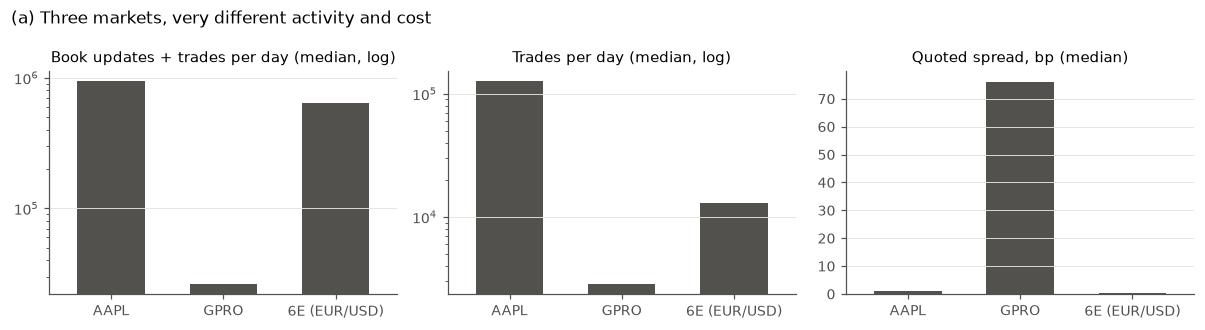

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=False)
for ax, col in zip(axes, ["events", "trades", "spread_bp"]):
    piv = stats.pivot(index="day", columns="security", values=col)[list(SECURITIES)]
    piv.median().plot.bar(ax=ax, color=MUTED, width=0.6, rot=0)
    ax.set_yscale("log" if col != "spread_bp" else "linear")
    ax.set_title({"events": "Book updates + trades per day (median, log)",
                  "trades": "Trades per day (median, log)",
                  "spread_bp": "Quoted spread, bp (median)"}[col])
    ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
fig.suptitle("(a) Three markets, very different activity and cost", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "a_activity")

## (b) Period: September 2026

21 trading days, Sep 1–30, with Labor Day (Sep 7) excluded. Data are pulled 09:30–16:00
ET. The first 10 minutes only warm up the 600-second lookbacks, and trading runs
09:40–15:50, as in the paper. The futures trade nearly 24 hours a day, but they're
cut to the same window so all three are compared over the same hours.

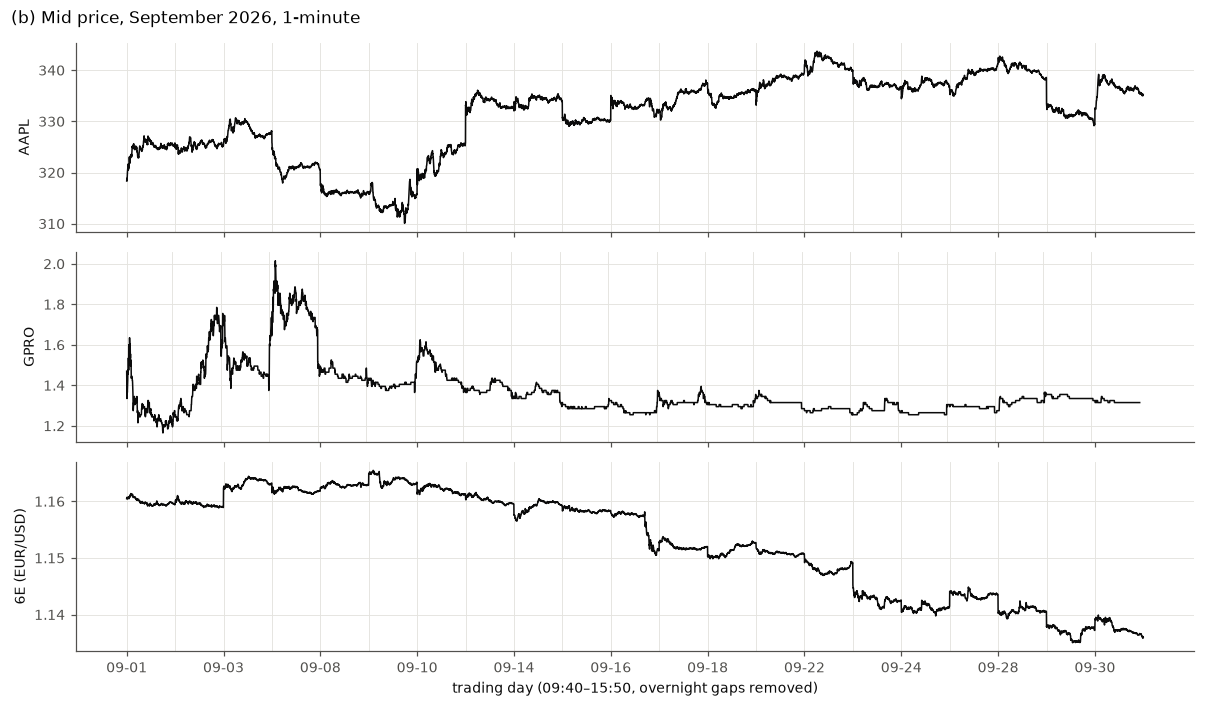

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
for ax, label in zip(axes, SECURITIES):
    s = minute_mid[[label, "day"]].dropna()
    x = np.arange(len(s))
    ax.plot(x, s[label].values, color=INK, lw=1)
    ax.set_ylabel(label)
    starts = np.flatnonzero(s.day.ne(s.day.shift()).values)
    for i in starts:
        ax.axvline(i, color=GRID, lw=0.6, zorder=0)
    ax.grid(axis="x", visible=False)
axes[-1].set_xticks(starts[::2], [d[5:] for d in s.day.iloc[starts[::2]]])
axes[-1].set_xlabel("trading day (09:40–15:50, overnight gaps removed)")
fig.suptitle("(b) Mid price, September 2026, 1-minute", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "b_prices")

In [7]:
daily = stats.pivot(index="day", columns="security", values="close")[list(SECURITIES)]
month_ret = (daily.iloc[-1] / stats.pivot(index="day", columns="security", values="open")[list(SECURITIES)].iloc[0] - 1)
print("Buy-and-hold over the month (first 09:40 mid to last 15:50 mid):")
print((month_ret * 100).round(2).astype(str) + "%")

Buy-and-hold over the month (first 09:40 mid to last 15:50 mid):
security
AAPL              5.31%
GPRO            -10.54%
6E (EUR/USD)     -2.11%
dtype: str


## (c) Signals

Two rules from the paper, implemented as its equations 3 and 6, and one of our own. All
three output a raw signal at each minute boundary, using only information available at
that moment. Lookbacks are counted in 1-minute intervals. When a rule is within its
band it goes **flat** (S = 0), as in the paper. Settings are one point from the
paper's Appendix A grid for the 60-second interval, and the same for all three
securities: s = 5, l = 10, b = 0. The data start at 09:30, so l = 10 is the longest
lookback that is fully warmed up by 09:40. The paper used pre-market data to start
earlier. With b = 0 both rules are plain crossovers. A 5 bp band (the next grid
point) leaves 6E's MA almost never trading, because EUR/USD rarely moves 5 bp in 10
minutes.

**1. Moving Average (MA), eq. 3.**
*ma(s, m)* is the average of the last *s* boundary mids.
Long if *ma(5, m) > (1 + b)·ma(10, m)*, short if *ma(5, m) < (1 − b)·ma(10, m)*,
flat otherwise. The rule follows the 5- vs 10-minute trend in the mid.

**2. On-Balance Volume (OBV), eq. 6.**
*obv* is the running sum, from the day's first trade, of each trade's volume: added
when the trade price ticks up, subtracted when it ticks down. The rule is the same
crossover as MA, applied to *obv* sampled at each boundary. It buys when signed
volume is trending up. (The paper's printed *obv* formula has the signs swapped;
the standard definition, which matches the paper's own description, is used.)

**3. Order-book imbalance (OBI), our own.**
*I = (bid size − ask size) / (bid size + ask size)* at the touch, averaged over the
10 seconds before the boundary. Long if *I* > 0.5, short if *I* < −0.5, flat
otherwise. A deep bid against a thin ask tends to come just before an uptick, because
the thin side is the one that gets used up first. Unlike the two paper rules, which
use 5–10 minutes of history, OBI's information is only seconds old. So it should be
the most sensitive to execution delay, which makes it a useful contrast for part (f).

The chart below shows one full AAPL session: the day on which OBI trades most, so all
three rules are visible. Dots are the minute boundaries at which the rules decide.

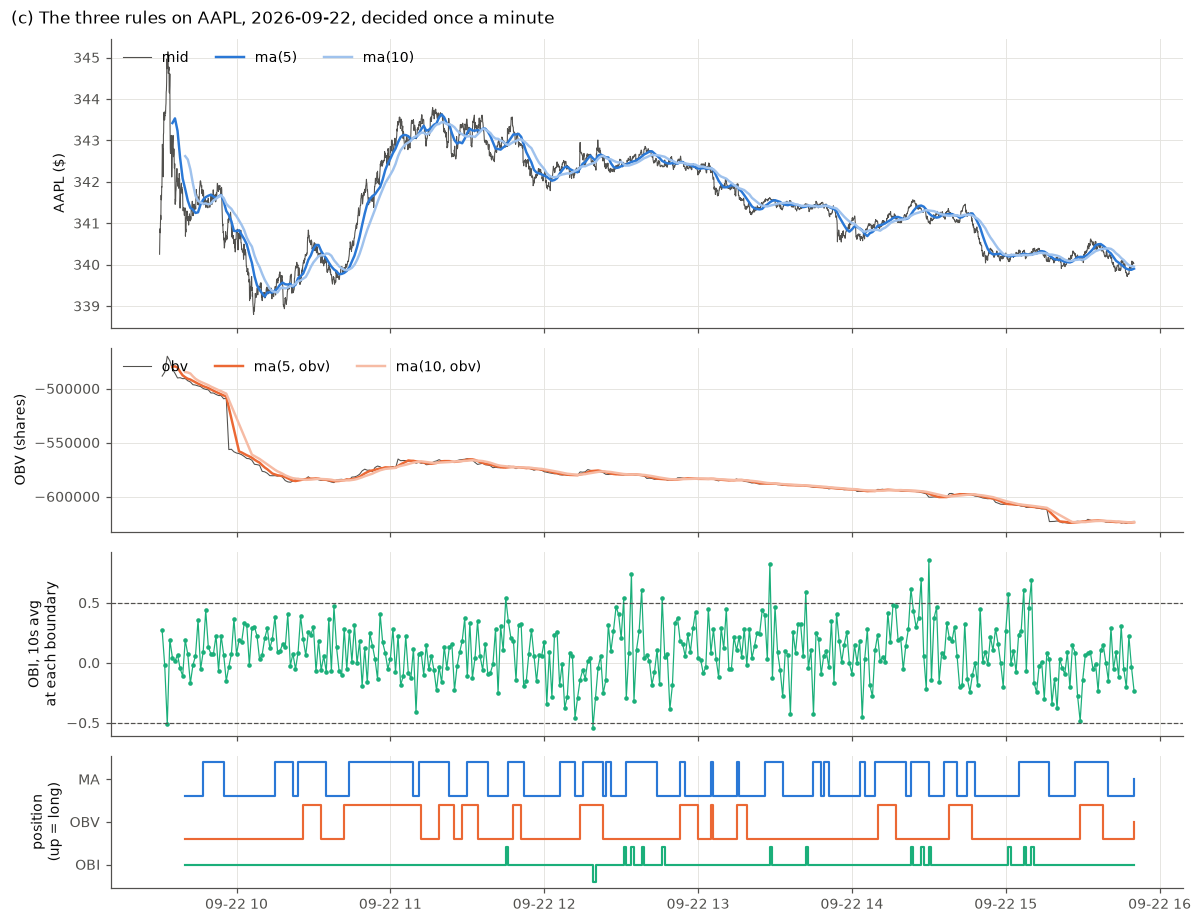

In [8]:
ex_day = all_legs.query("security == 'AAPL' and signal == 'OBI' and delay == 0").day.value_counts().idxmax()
df_ex = load_day("AAPL", ex_day)
g_ex = at_boundaries(df_ex)
S_ex, aux_ex = signals(g_ex)
sess_ex = df_ex.between_time("09:30", TRADE_END).mid.resample("5s").last()

fig, axes = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1.4, 1.4, 1]})
ax = axes[0]
ax.plot(sess_ex, color=MUTED, lw=0.7, label="mid")
ax.plot(aux_ex["ma_s"], color=SIG_COLOR["MA"], lw=1.6, label=f"ma({MA_S})")
ax.plot(aux_ex["ma_l"], color=shade(SIG_COLOR["MA"], 0.45), lw=1.6, label=f"ma({MA_L})")
ax.set_ylabel("AAPL ($)")
ax.legend(loc="upper left", ncol=3)

ax = axes[1]
ax.plot(g_ex.obv, color=MUTED, lw=0.7, label="obv")
ax.plot(aux_ex["obv_s"], color=SIG_COLOR["OBV"], lw=1.6, label=f"ma({OBV_S}, obv)")
ax.plot(aux_ex["obv_l"], color=shade(SIG_COLOR["OBV"], 0.45), lw=1.6, label=f"ma({OBV_L}, obv)")
ax.set_ylabel("OBV (shares)")
ax.legend(loc="upper left", ncol=3)

ax = axes[2]
ax.plot(g_ex.imb, color=SIG_COLOR["OBI"], lw=0.8, marker="o", ms=2)
for th in (OBI_TH, -OBI_TH):
    ax.axhline(th, color=MUTED, lw=0.8, ls="--")
ax.set_ylabel(f"OBI, {OBI_WINDOW} avg\nat each boundary")

ax = axes[3]
tgt_ex = pd.DataFrame({sig: target(S_ex[sig]) for sig in SIGNALS})
for k, sig in enumerate(SIGNALS):
    ax.step(tgt_ex.index, tgt_ex[sig] * 0.8 + 2 * (2 - k), where="post", color=SIG_COLOR[sig], lw=1.4)
ax.set_yticks([4, 2, 0], SIGNALS)
ax.set_ylabel("position\n(up = long)")
ax.grid(axis="y", visible=False)
fig.suptitle(f"(c) The three rules on AAPL, {ex_day}, decided once a minute", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "c_signals_example")

In [9]:
turnover = (all_legs[all_legs.delay == 0].groupby(["security", "signal"], sort=False)
            .size().div(len(DAYS)).unstack()[SIGNALS])
print("Round trips per day (0 delay):")
turnover.round(1)

Round trips per day (0 delay):


signal,MA,OBV,OBI
security,,,
AAPL,43.5000,33.0000,5.1000
GPRO,24.4000,32.8000,39.5000
6E (EUR/USD),43.4000,37.6000,38.7000


## (d) Execution delays

Delays of **0 ms, 100 ms and 1 s** are applied exactly as in the paper: the order is
sent at the minute boundary and fills on the quote standing at *boundary + delay*.
The signal, and therefore the intended position, is identical across delays. Only
the fill price changes, so any difference in P&L is purely the cost of being slow.

Part (f) also runs the paper's full grid (0, 10, 20, 50, 100, 200, 500 ms, 1 s) to
draw the Figure 6 curve. The chart below shows why delay matters: for every order
sent, how often the mid has already changed by the time the order fills.

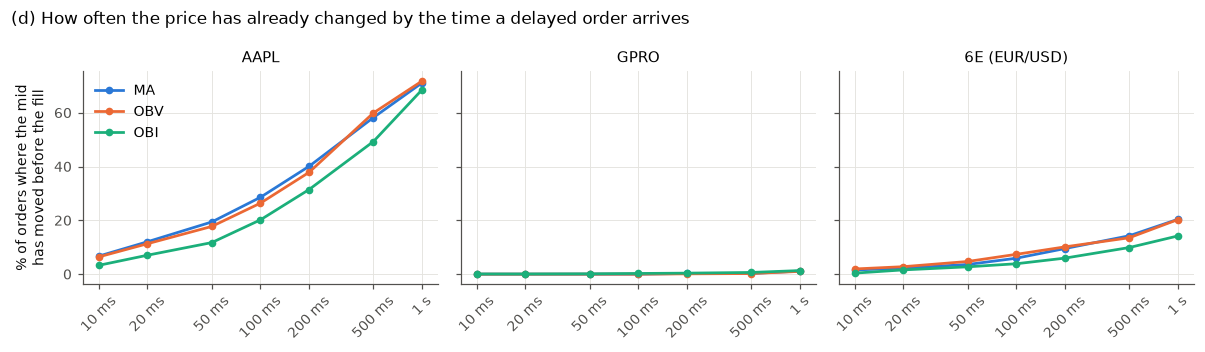

In [10]:
dr = drift.groupby(["security", "signal", "delay"]).agg(
    adverse_bp=("drift_bp", "mean"), shortfall_bp=("shortfall_bp", "mean"),
    p_moved=("moved", "mean")).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, label in zip(axes, SECURITIES):
    for sig in SIGNALS:
        s = dr[(dr.security == label) & (dr.signal == sig)]
        ax.plot(s.delay, s.p_moved * 100, color=SIG_COLOR[sig], marker="o", ms=4, label=sig)
    ax.set_xscale("log")
    ax.set_xticks(DELAY_GRID[1:], [ms_label(d) for d in DELAY_GRID[1:]], rotation=45)
    ax.minorticks_off()
    ax.set_title(label)
axes[0].set_ylabel("% of orders where the mid\nhas moved before the fill")
axes[0].legend()
fig.suptitle("(d) How often the price has already changed by the time a delayed order arrives",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "d_price_moved_before_fill")

## (e) Total returns on \$1,000,000

One P&L report for each security × signal × delay: 27 in all. The spec counts 18;
the full 3 × 3 × 3 grid is shown here. Every position is \$1,000,000 long or short.
As in the paper, returns are summed over round trips, not compounded, so the P&L is
\$1M × Σ r and a −100% total means \$1M lost in aggregate.

Columns:
* `pnl`, `return_pct`: total P&L and return after spread costs
* `mid_return_pct`: the same trades priced at the mid, before spread costs
* `round_trips`, `win_rate`, `avg_trade_bp`: per-trade statistics
* `sharpe`: annualised, from the 21 daily returns
* `max_dd_pct`: worst peak-to-trough fall of the cumulative P&L, as % of \$1M

In [11]:
def report(g):
    g = g.sort_values("t_exit")
    cum = np.r_[0.0, np.cumsum(g.r.values)]
    day_r = g.groupby("day").r.sum().reindex(DAYS, fill_value=0.0)
    return pd.Series({
        "pnl": BOOK * cum[-1],
        "return_pct": cum[-1] * 100,
        "mid_return_pct": g.r_mid.sum() * 100,
        "round_trips": len(g), "win_rate": (g.r > 0).mean() * 100 if len(g) else np.nan,
        "avg_trade_bp": g.r.mean() * 1e4 if len(g) else np.nan,
        "sharpe": day_r.mean() / day_r.std() * np.sqrt(252) if day_r.std() > 0 else np.nan,
        "max_dd_pct": (cum - np.maximum.accumulate(cum)).min() * 100,
    })


reports = (all_legs.groupby(["security", "signal", "delay"], sort=False)
           .apply(report, include_groups=False))
reports = reports.reindex(pd.MultiIndex.from_product([list(SECURITIES), SIGNALS, DELAY_GRID],
                                                     names=["security", "signal", "delay"]))
reports.to_csv(OUT / "e_pnl_reports_full_grid.csv")
pnl = reports.loc[(slice(None), slice(None), DELAYS), :]
pnl.to_csv(OUT / "e_pnl_reports.csv")
pnl.style.format({
    "pnl": "${:,.0f}", "return_pct": "{:.2f}%", "mid_return_pct": "{:.2f}%",
    "round_trips": "{:,.0f}", "win_rate": "{:.1f}%", "avg_trade_bp": "{:.2f}", "sharpe": "{:.2f}",
    "max_dd_pct": "{:.2f}%",
})

Cumulative P&L, one panel per security × signal. The colour is the signal and gets
lighter (and dashed) as the delay grows. Each panel has its own y-scale, because the
scale differs a lot between assets.

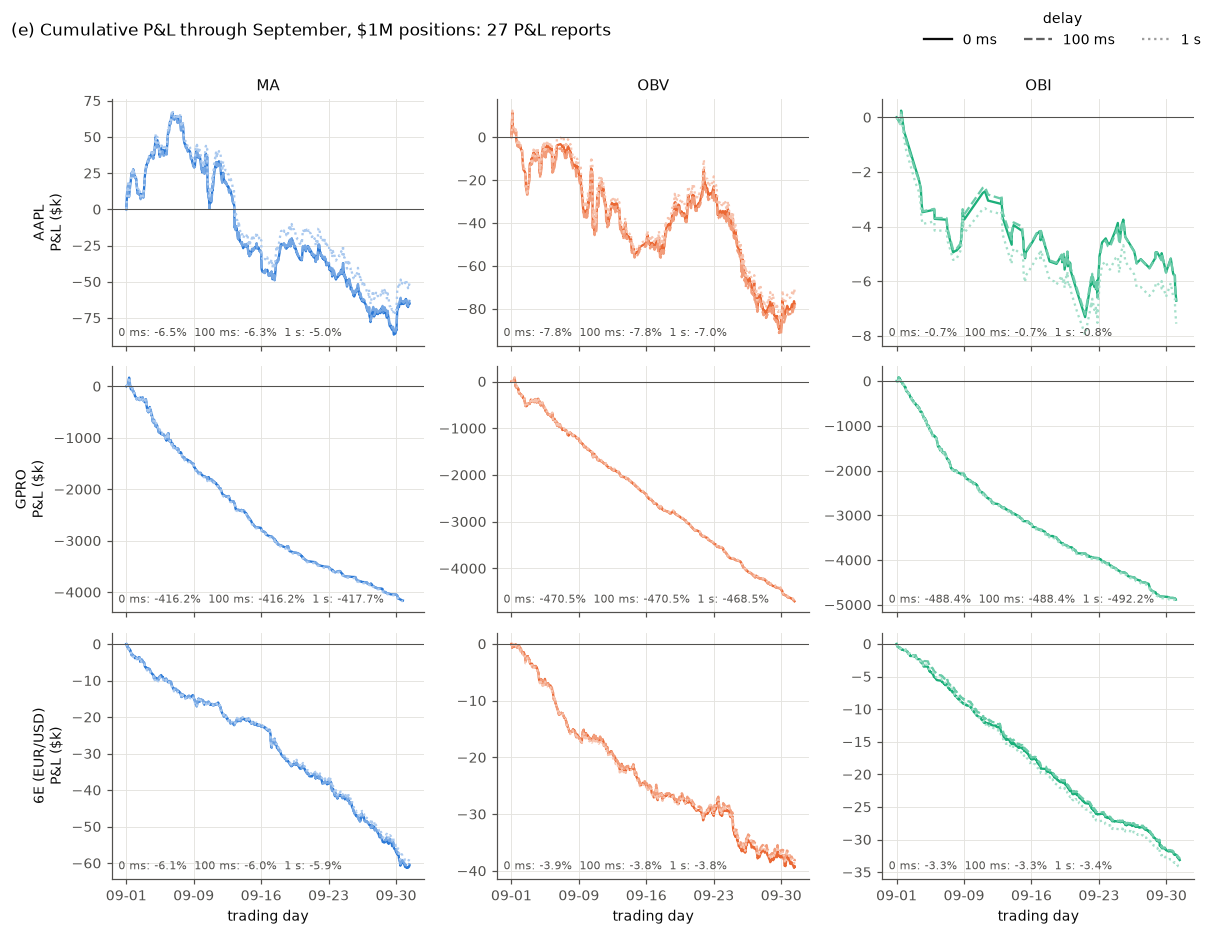

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8.5), sharex=True)
day_pos = {d: i for i, d in enumerate(DAYS)}
sess_len = pd.Timedelta(f"{TRADE_END}:00") - pd.Timedelta(f"{TRADE_START}:00")
for i, label in enumerate(SECURITIES):
    for j, sig in enumerate(SIGNALS):
        ax = axes[i, j]
        for d in DELAYS:
            g = all_legs[(all_legs.security == label) & (all_legs.signal == sig) & (all_legs.delay == d)]
            g = g.sort_values("t_exit")
            intraday = (g.t_exit - g.t_exit.dt.normalize() - pd.Timedelta(f"{TRADE_START}:00")) / sess_len
            x = np.r_[0, g.day.map(day_pos).values + intraday.clip(0, 1).values]
            y = np.r_[0.0, np.cumsum(g.r.values)] * BOOK / 1e3
            strength, ls = DELAY_STYLE[d]
            ax.plot(x, y, color=shade(SIG_COLOR[sig], strength), ls=ls, lw=1.5)
        ax.axhline(0, color=MUTED, lw=0.7)
        if i == 0:
            ax.set_title(sig, color=INK)
        if j == 0:
            ax.set_ylabel(f"{label}\nP&L ($k)")
        r = pnl.loc[(label, sig)]
        ax.text(0.02, 0.04, "  ".join(f"{ms_label(d)}: {r.loc[d, 'return_pct']:+.1f}%" for d in DELAYS),
                transform=ax.transAxes, fontsize=7.5, color=MUTED)
for ax in axes[-1]:
    ax.set_xticks(range(0, len(DAYS), 5), [DAYS[k][5:] for k in range(0, len(DAYS), 5)])
    ax.set_xlabel("trading day")
handles = [plt.Line2D([], [], color=shade(INK, s), ls=ls, lw=1.5) for s, ls in DELAY_STYLE.values()]
fig.legend(handles, [ms_label(d) for d in DELAY_STYLE], loc="upper right", ncol=3, title="delay")
fig.suptitle("(e) Cumulative P&L through September, $1M positions: 27 P&L reports",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "e_equity_curves")

Return before and after spread costs. The gap between the two bars is what crossing
the spread costs each strategy (0 delay).

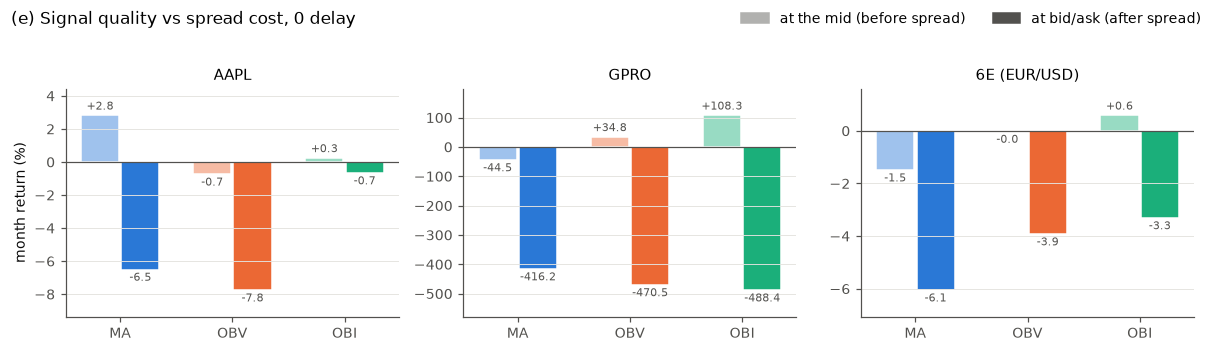

In [13]:
z = pnl.xs(0, level="delay")[["mid_return_pct", "return_pct"]]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, label in zip(axes, SECURITIES):
    zz = z.loc[label]
    x = np.arange(len(SIGNALS))
    for off, col, s in [(-0.18, "mid_return_pct", 0.45), (0.18, "return_pct", 1.0)]:
        bars = ax.bar(x + off, zz[col], 0.34, color=[shade(SIG_COLOR[g], s) for g in SIGNALS],
                      edgecolor="white", linewidth=1)
        ax.bar_label(bars, fmt="%+.1f", fontsize=7, color=MUTED, padding=2)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xticks(x, SIGNALS)
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.15)
axes[0].set_ylabel("month return (%)")
handles = [plt.Rectangle((0, 0), 1, 1, color=shade(MUTED, s)) for s in (0.45, 1.0)]
fig.legend(handles, ["at the mid (before spread)", "at bid/ask (after spread)"], loc="upper right", ncol=2)
fig.suptitle("(e) Signal quality vs spread cost, 0 delay", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "e_mid_vs_touch")

## (f) Cost of delay

The paper's Figure 6 measures the **importance of speed** in relative terms (section
4 and footnote 22). On each day *i*, the performance with delay *d*, P_i(d), is
compared with the performance with instantaneous execution, P_i(0). The daily
relative differences are then averaged over all days; days on which P_i(0) = 0 are
excluded:

$$\text{IoS}(d) = \frac{1}{N}\sum_i \frac{P_i(d) - P_i(0)}{|P_i(0)|} \times 100\%$$

The denominator is |P_i(0)| so that a negative number always means "worse than
instantaneous", including on days the strategy loses money. The paper averages
many strategies each day before dividing. Here each rule is a single strategy, so a
day with P_i(0) close to zero can produce an extreme ratio. The paper's robustness
section (5.2) handles this by truncating each relative difference at ±100%, and
that truncated version is used here. Two absolute measures sit beside it:

* percentage points of the \$1M position over the month, R(d) − R(0);
* bp per round trip, avg trade return(d) − avg trade return(0).

The paper's grid, 0 / 10 / 20 / 50 / 100 / 200 / 500 ms / 1 s, is used, with the two
required delays shaded.

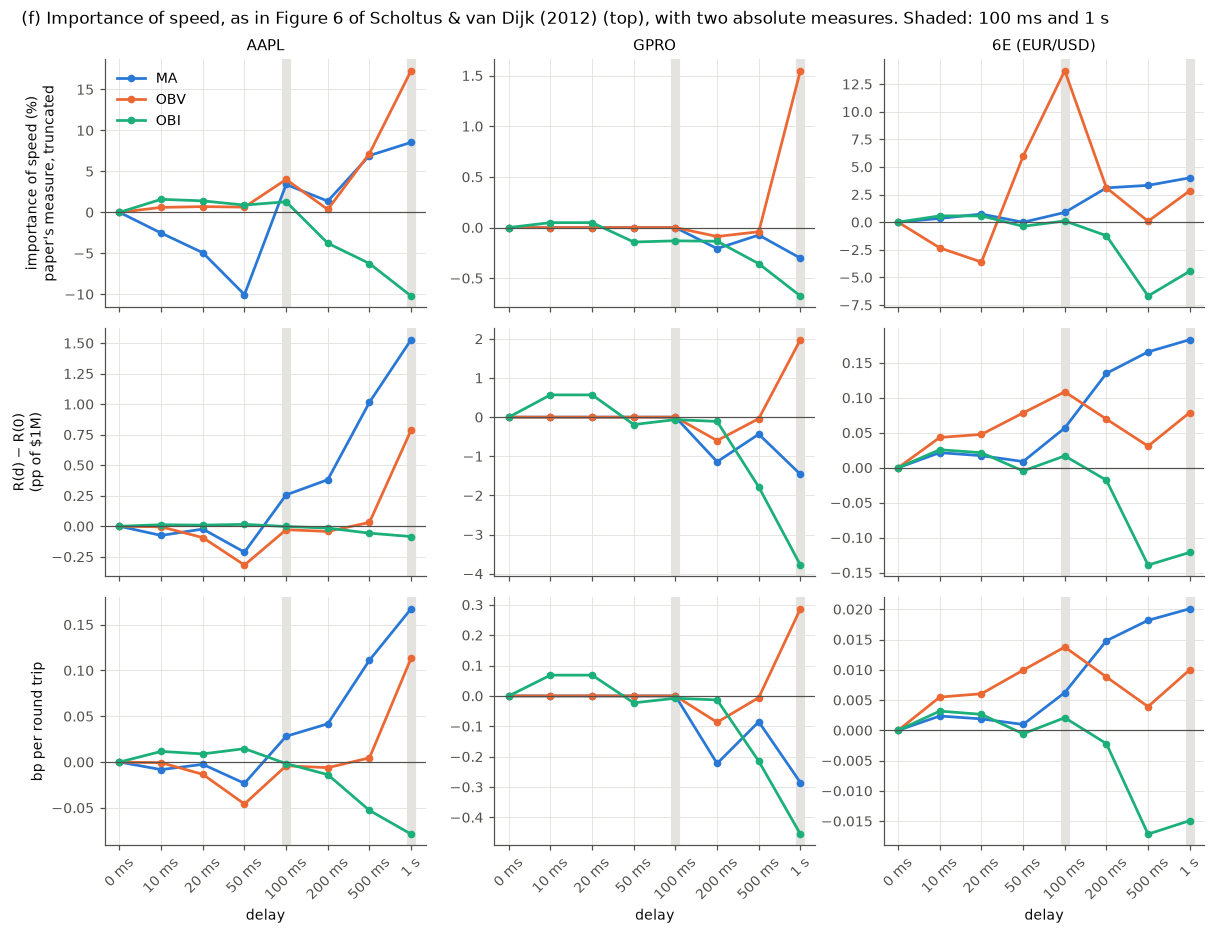

In [14]:
day_perf = (all_legs.groupby(["security", "signal", "delay", "day"]).r.sum()
            .unstack("day").reindex(columns=DAYS, fill_value=0.0).fillna(0.0)
            .reindex(reports.index, fill_value=0.0))
p0 = day_perf.xs(0, level="delay").reindex(day_perf.index.droplevel("delay")).values
with np.errstate(divide="ignore", invalid="ignore"):
    rel = np.where(p0 != 0, (day_perf.values - p0) / np.abs(p0) * 100, np.nan)
rel_trunc = np.clip(rel, -100, 100)

base = lambda col: reports[col].xs(0, level="delay").reindex(reports.index.droplevel("delay")).values
cod = pd.DataFrame({
    "ios_pct": np.nanmean(rel_trunc, axis=1),
    "ios_untruncated_pct": np.nanmean(rel, axis=1),
    "cod_pp": reports.return_pct - base("return_pct"),
    "cod_bp_per_trade": reports.avg_trade_bp - base("avg_trade_bp"),
}, index=reports.index)
cod["cod_usd"] = cod.cod_pp / 100 * BOOK
cod.to_csv(OUT / "f_cost_of_delay_full_grid.csv")

fig, axes = plt.subplots(3, 3, figsize=(11, 8.6), sharex=True)
xs = np.arange(len(DELAY_GRID))
rows = [("ios_pct", "importance of speed (%)\npaper's measure, truncated"),
        ("cod_pp", "R(d) − R(0)\n(pp of $1M)"),
        ("cod_bp_per_trade", "bp per round trip")]
for row, (col, ylab) in enumerate(rows):
    for ax, label in zip(axes[row], SECURITIES):
        for sig in SIGNALS:
            ax.plot(xs, cod.loc[(label, sig), col].values, color=SIG_COLOR[sig], marker="o", ms=4, label=sig)
        for d in (100, 1000):
            ax.axvline(DELAY_GRID.index(d), color=GRID, lw=6, zorder=0)
        ax.axhline(0, color=MUTED, lw=0.8)
        if row == 0:
            ax.set_title(label)
        if row == len(rows) - 1:
            ax.set_xticks(xs, [ms_label(d) for d in DELAY_GRID], rotation=45)
            ax.set_xlabel("delay")
    axes[row, 0].set_ylabel(ylab)
axes[0, 0].legend()
fig.suptitle("(f) Importance of speed, as in Figure 6 of Scholtus & van Dijk (2012) (top), "
             "with two absolute measures. Shaded: 100 ms and 1 s", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save(fig, "f_cost_of_delay")

The two required delays, as a table: the paper's relative measure (truncated, and
untruncated for reference), percentage points of the \$1M position, dollars, and bp
per round trip.

In [15]:
cod_req = cod.loc[(slice(None), slice(None), [100, 1000]), :].unstack("delay")
cod_req.columns = [f"{a}_{ms_label(b).replace(' ', '')}" for a, b in cod_req.columns]
cod_req.to_csv(OUT / "f_cost_of_delay.csv")
cod_req.style.format({c: ("${:+,.0f}" if "usd" in c else "{:+.3f}") for c in cod_req.columns})

## Commentary

### Market conditions

Each day is split at the month's median by two measures:
* **Volatility**: the standard deviation of 1-minute mid returns.
* **Trend efficiency**: |open-to-close move| ÷ the sum of absolute 1-minute moves.
  It is near 1 on a day that moves steadily one way and near 0 on a choppy day.

The table gives the average daily return (%, 0 delay, after spread costs) in each
half.

In [16]:
day_ret = (all_legs[all_legs.delay == 0].groupby(["security", "signal", "day"])
           .r.sum().unstack("signal").reindex(columns=SIGNALS))
day_ret = day_ret.reindex(pd.MultiIndex.from_product([list(SECURITIES), DAYS], names=["security", "day"]),
                          fill_value=0.0) * 100
cond = stats.set_index(["security", "day"])[["vol_1min_bp", "trend_eff"]]
cond["vol"] = cond.groupby(level=0).vol_1min_bp.transform(lambda v: np.where(v > v.median(), "high vol", "low vol"))
cond["trend"] = cond.groupby(level=0).trend_eff.transform(lambda v: np.where(v > v.median(), "trending", "choppy"))
regimes = pd.concat({
    k: day_ret.join(cond[k]).groupby([pd.Grouper(level=0), k])[SIGNALS].mean().unstack(k)
    for k in ["vol", "trend"]}, axis=1)
regimes.to_csv(OUT / "commentary_regimes.csv")
regimes.round(3)

vol                                                 trend  \
                   MA               OBV               OBI                MA   
             high vol  low vol high vol  low vol high vol  low vol   choppy   
security                                                                      
6E (EUR/USD)  -0.3050  -0.2730  -0.1430  -0.2270  -0.1370  -0.1760  -0.2780   
AAPL          -0.2060  -0.4040  -0.2590  -0.4700  -0.0370  -0.0280  -0.8290   
GPRO         -26.4730 -13.7750 -22.2120 -22.5750 -32.0350 -15.2760 -19.8520   

                                                           
                           OBV               OBI           
             trending   choppy trending   choppy trending  
security                                                   
6E (EUR/USD)  -0.3000  -0.2510  -0.1160  -0.1520  -0.1640  
AAPL           0.2610  -0.3800  -0.3580  -0.0150  -0.0510  
GPRO         -19.7880 -24.3800 -20.2270 -25.5930 -20.6850

### Tick frequency and the cost of delay

Each market's event rate, set against what a delayed order costs, in bp, at 100 ms
and 1 s. The cost is split into two parts:
* `mid`: how far the mid moved in the direction of the trade before the fill
* `fill`: the full change in the price paid, which adds any change in the half-spread

In [17]:
tick = summary[["events_per_sec", "median_gap_ms", "spread_bp"]].copy()
for d in (100, 1000):
    tag = ms_label(d).replace(" ", "")
    tick[f"pct_moved_{tag}"] = dr[dr.delay == d].groupby("security").p_moved.mean() * 100
    for col, name in [("adverse_bp", "mid"), ("shortfall_bp", "fill")]:
        m = dr[dr.delay == d].pivot(index="security", columns="signal", values=col)[SIGNALS]
        tick = tick.join(m.add_prefix(f"{name}_{tag}_"))
tick.to_csv(OUT / "commentary_tick_frequency.csv")
tick.T.round(3)

security,AAPL,GPRO,6E (EUR/USD)
events_per_sec,40.3580,2.4430,26.5430
median_gap_ms,0.0320,2.0190,0.1320
spread_bp,0.9040,76.0460,0.4330
pct_moved_100ms,25.0520,0.0850,5.7190
mid_100ms_MA,-0.0390,0.0000,-0.0020
mid_100ms_OBV,-0.0250,0.0000,-0.0040
mid_100ms_OBI,0.0030,0.0050,-0.0010
fill_100ms_MA,-0.0190,0.0000,-0.0030
fill_100ms_OBV,0.0030,0.0000,-0.0070
fill_100ms_OBI,0.0010,0.0060,-0.0010


### Discussion

**The headline.** No rule makes money after crossing the spread, on any security, at
any delay. Some rules do have an edge before costs. At the mid, MA makes +2.8% on AAPL,
OBI makes +0.3% on AAPL and +0.6% on 6E, and on GPRO OBV and OBI make +35% and +108%.
On GPRO that edge is swamped by a 76 bp spread paid 500–800 times a month: summed over
the month, it comes to a loss of 4–5× the \$1M position. As in the paper, the spread is
the first-order cost and delay is second-order.

**How this compares with the paper's Figure 6.** The paper finds the importance of
speed flat up to 200 ms, then falling to about −3% at 1 s. Our **OBI** curves have
that shape. On AAPL the measure is between −1% and +2% up to 100 ms, then −3.8% at
200 ms, −6.2% at 500 ms and −10.2% at 1 s. On 6E it falls to −6.7% at 500 ms and
−4.4% at 1 s. **MA and OBV get *better* when delayed**: on AAPL, +8.5% and +17% at
1 s on the paper's measure, or +1.5 and +0.8 points of the \$1M. That also matches
the paper. It finds speed only matters for strategies that make money; for losing
strategies, being slow can help (section 4, Figures 7–8 and footnote 28). Every one
of our strategies loses after the spread. The mechanism shows in the tick-frequency
table: one second after an AAPL MA or OBV order, the mid has moved about 0.1 bp *in
our favour*. These rules buy after a 5-minute rise, at a round-minute boundary, which
is exactly when the paper finds activity spikes (its Figures 3–4). The price tends to
give a little back, so a slower fill is a cheaper fill. OBI, whose information is
only seconds old, is the one rule where the price keeps moving against a slow order.

**(a) Which asset is hurt most by delay, and why?**
On the 60-second clock, the answer is mostly "how often does the price change in the
first second after a minute boundary?"

* **AAPL is the most exposed**: its mid has moved before the fill in 25% of orders at
  100 ms and 70% at 1 s. Each move is only a cent or two, but for a fresh signal (OBI)
  the moves go against us, giving the clearest Figure 6 shape of the three.
* **6E sits in the middle**: 6% at 100 ms, 18% at 1 s. Its slow rules barely react to
  delay (under 0.02 bp per round trip), and OBI loses up to 0.017 bp per round trip.
* **GPRO is almost immune**: its quote changes within 100 ms of a minute boundary in
  only 0.1% of orders, and within 1 s in 1.2%. Delays up to 100 ms cost exactly
  nothing for MA and OBV. When a GPRO move does arrive it is huge (half a tick is
  ~38 bp), so OBI's 1 s delay still costs 0.46 bp per round trip, the largest
  per-trade cost in the table. The cost of delay is the chance the price moves in the
  delay window, times how big a move is. GPRO has a tiny chance and a huge move;
  AAPL has a high chance and a tiny move.

**(b) Do the signals behave differently in different market conditions?**
Yes (see the regime table; each half is only ~10 days, so treat this as suggestive):

* **MA is a trend rule**: on AAPL it makes +0.26%/day on trending days and loses
  −0.83%/day on choppy days, when it is whipsawed across the crossover.
* **Volatility hurts the rules that trade on GPRO**: MA loses −26%/day on its
  high-volatility days against −14% on quiet ones, and OBI −32% against −15%. Busy days
  produce more crossings, and each one pays the 76 bp spread.
* **OBV has no edge at this horizon**: it loses even at the mid on AAPL and is flat at
  the mid on 6E, in every regime. Signing volume by tick direction is a daily-bar idea
  that doesn't carry over to minutes.
* The paper reports a related volatility effect for speed itself: on high-VIX days
  delays of 50–200 ms slightly *improved* performance, while on low-VIX days speed
  mattered more.

**(c) Does tick frequency matter, and how would we use it?**
The raw message rate is the wrong measure. 6E has 27 book updates a second, close to
AAPL's 40, but its mid changes within 100 ms of a boundary only a quarter as often
(6% vs 25%). Most 6E updates change queue sizes at an unchanged price. What matters is
the rate of **price** changes in the delay window, against the strategy's expected
profit per trade. In practice:

1. **Match the investment in speed to the asset and the signal.** For a 5–10 minute
   trend rule, or for any rule on GPRO, sub-second latency buys nothing. For a
   seconds-old signal like OBI on AAPL, being slower than ~200 ms costs real money.
2. **Don't decide on the round minute.** The paper's activity spikes at interval
   changes, and our MA/OBV results suggest the price overshoots there. Offsetting the
   decision clock, or waiting a beat for a losing-type rule, gets a better fill.
3. **Add the expected delay cost to the entry threshold**: trade only when the
   expected move is larger than the spread plus *P(price changes within the latency)
   × the expected move*.
4. **In large-tick markets, stop paying the spread.** GPRO's OBI is right often
   enough to make +108% at the mid, which makes it a signal for *where to rest a
   limit order*, not for when to cross.

**Caveats.** One month, and one parameter setting per rule; the paper averages 27,424
rule variants per day, which smooths its Figure 6. Our relative measure is truncated
at ±100% per day, as in the paper's section 5.2. Untruncated, a few days with 0 ms
P&L near zero dominate it (the 6E OBV values above). Lookbacks are capped at 10
minutes because the data start at 09:30. Every order fills in full at the touch:
fine for AAPL and 6E, but unrealistic for \$1M of GPRO. Equity quotes are
Nasdaq-only. There are no fees or rebates.